# Canopy air temperatures on opposite forest slopes

This notebook explores the EnviDat dataset

> Haagmans, V., Mazzotti, G., Jonas, T. (2025). *Canopy air temperatures in subalpine forests during three snow seasons.*
> EnviDat. [doi:10.16904/envidat.722](https://doi.org/10.16904/envidat.722) (CC-BY-4.0)

which accompanies the paper *Contrasting canopy air temperatures across complex terrain during the snow season* (JGR Atmospheres).
In three winters (Flüela 2023, Monstein 2024 and 2025, near Davos), ventilated weather stations measured air temperature
2.5 m above ground inside the forest, **on a north-facing and a south-facing slope of the same valley**.

What we'll do:

1. Look inside the archive (MATLAB scripts, processed `.mat` files, raw logger files).
2. Read raw logger files: a Campbell TOA5 station file and a HOBO CSV.
3. Read the authors' processed MATLAB `timetable`s with `mat-io` and harmonise them as their scripts do.
4. **Reproduce Figure 2 of the paper in Python**, and check it against the original.
5. Check that the 15-min data used by the companion app gives the same answer.

Everything is read **directly from the zip on the data connector** with Python's `zipfile`; nothing is extracted into the project.

The reusable code lives in `src/canopy_temps/` (`prepare.py` for reading and harmonising, `analysis.py` for the computations),
and the same functions drive the Panel app in `app.py`.

In [1]:
import os
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

from canopy_temps import analysis, prepare

# Mounted read-only by the Renku data connector; override with $CANOPY_ZIP elsewhere.
ZIP = Path(os.environ.get("CANOPY_ZIP", prepare.DEFAULT_ZIP))
ar = prepare.Archive(ZIP)
ZIP

PosixPath('/home/renku/work/canopy-air-temperatures-in-sub-doi-10.16904-envidat.722/jgr_atmospheres_haagmans.zip')

## 1. What's in the archive?

One 244 MB zip. Let's summarise it by folder:

In [2]:
info = pd.DataFrame(
    [(i.filename, i.file_size) for i in zipfile.ZipFile(ZIP).infolist() if not i.is_dir()],
    columns=["path", "bytes"],
)
info["folder"] = info["path"].str.split("/").str[1:3].str.join("/")
info["ext"] = info["path"].str.extract(r"(\.[^./]+)$")
summary = info.groupby(["folder", "ext"]).agg(files=("path", "size"), MB=("bytes", lambda b: round(b.sum() / 1e6, 1)))
summary

files     MB
folder                                             ext                
additional_data/correction_factors                 .mat       6    0.0
additional_data/snow_cover                         .csv       2    0.0
                                                   .mat       1    0.0
                                                   .xlsx      2    0.0
functions/HOBO_import_AMPM_timestamp.m             .m         1    0.0
functions/HOBO_import_AMPM_timestamp_Vcal.m        .m         1    0.0
functions/HOBO_import_timestamp.m                  .m         1    0.0
functions/SolarAzEl                                .m         2    0.0
                                                   .txt       1    0.0
output_figures/Figure2_JGRA_Haagmans_et_al_2025... .png       1    0.1
output_figures/Figure3_JGRA_Haagmans_et_al_2025... .png       1    0.1
output_figures/Figure4_JGRA_Haagmans_et_al_2025... .png       1    0.1
output_figures/Figure5_JGRA_Haagmans_et_al_2025... .png       1    0.4
output_figures/Figure6_JGRA_Haagmans_et_al_2025... .png       1    0.1
output_figures/Figure7A_JGRA_Haagmans_et_al_202... .png       1    0.2
output_figures/Figure7BCD_JGRA_Haagmans_et_al_2... .png       1    0.4
output_figures/Figure7E_JGRA_Haagmans_et_al_202... .png       1    0.1
output_figures/Figure8_JGRA_Haagmans_et_al_2025... .png       1    0.3
output_figures/FigureA1_JGRA_Haagmans_et_al_202... .png       1    0.1
output_figures/FigureA2_JGRA_Haagmans_et_al_202... .png       1    0.2
output_figures/FigureA3A_JGRA_Haagmans_et_al_20... .png       1    0.2
output_figures/FigureA3BD_JGRA_Haagmans_et_al_2... .png       1    0.4
output_figures/FigureA3E_JGRA_Haagmans_et_al_20... .png       1    0.1
output_figures/FigureA4_JGRA_Haagmans_et_al_202... .png       1    0.1
primary_data/AWS                                   .dat      18  207.9
                                                   .dvd       9   74.9
                                                   .txt       3    0.0
primary_data/HOBO                                  .csv      23    7.7
                                                   .hobo      2    0.1
                                                   .txt       2    0.0
processed_data/HOBO_fluela_202223.mat              .mat       1    2.5
processed_data/HOBO_monstein_202324.mat            .mat       1    1.6
processed_data/HOBO_monstein_202425.mat            .mat       1    1.7
processed_data/SC_periods_Fluela2223.mat           .mat       1    0.0
processed_data/SC_periods_Monstein2324.mat         .mat       1    0.0
processed_data/SC_periods_Monstein2425.mat         .mat       1    0.0
processed_data/snowfall_fluela2223.mat             .mat       1    0.0
processed_data/snowfall_monstein2324.mat           .mat       1    0.0
processed_data/ventilated_stations_fluela_20222... .mat       1    6.2
processed_data/ventilated_stations_monstein_202... .mat       1   34.2
processed_data/ventilated_stations_monstein_202... .mat       1   93.2
scripts_figures/figure_2.m                         .m         1    0.0
scripts_figures/figure_3.m                         .m         1    0.0
scripts_figures/figure_4.m                         .m         1    0.0
scripts_figures/figure_5.m                         .m         1    0.0
scripts_figures/figure_6.m                         .m         1    0.0
scripts_figures/figure_7.m                         .m         1    0.0
scripts_figures/figure_8.m                         .m         1    0.0
scripts_figures/figure_A1.m                        .m         1    0.0
scripts_figures/figure_A2.m                        .m         1    0.0
scripts_figures/figure_A3.m                        .m         1    0.0
scripts_figures/figure_A4.m                        .m         1    0.0

Roughly:

* `primary_data/AWS/*/RAW` are Campbell Scientific CR1000 loggers (TOA5 format), 60 s in the forest and 15 s at an open site.
* `primary_data/HOBO`: passive HOBO loggers on tree stems at 0.5/1/2.5/4.5 m. Several CSV dialects, one of them German.
* `processed_data`: the authors' cleaned, cross-calibrated series, saved as MATLAB `timetable`s.
* `scripts_figures`: MATLAB R2024a scripts that generate every figure from `processed_data`.

## 2. Raw logger files

### 2a. Weather stations (TOA5)

TOA5 files have four header lines: file info, column names, units and aggregation type. pandas handles them with `skiprows`.

In [3]:
def read_toa5(rel):
    df = pd.read_csv(ar.open(rel), skiprows=[0, 2, 3], index_col="TIMESTAMP", parse_dates=True, na_values=["NAN"])
    df.index.name = "time"
    return df

shd2 = read_toa5("primary_data/AWS/2023_FLUELA/RAW/CR1000_SLFSHD2_MetStation2_60sec.dat")
shd3 = read_toa5("primary_data/AWS/2023_FLUELA/RAW/CR1000_SLFSHD3_MetStation3_60sec.dat")
shd2.head()

,RECORD,BattV_Avg,PTemp_C_Avg,AirTC_Avg,RH,AirTC2_Avg,Rtherm2_Avg
time,,,,,,,
2022-12-31 23:59:00,52329,12.07,4.536,5.263,58.91,5.378,1021
2023-01-01 00:00:00,52330,12.07,4.536,5.199,59.32,5.326,1021
2023-01-01 00:01:00,52331,12.07,4.536,5.118,59.69,5.320,1021
2023-01-01 00:02:00,52332,12.07,4.532,5.031,60.81,5.280,1021
2023-01-01 00:03:00,52333,12.07,4.522,4.992,60.23,5.273,1021


**Which station is on which slope?** The README for Flüela says SHD2 = north and SHD3 = south. But the READMEs in
`AWS/2024_MONSTEIN` and `AWS/2025_MONSTEIN` look swapped: each describes the *other* winter's loggers. The 2025 figure
scripts also contradict one of them on which station is north. So rather than trust the text, let's **check against the
processed data**. The right pairing should differ only by a near-constant calibration offset, i.e. the
*standard deviation* of the difference should be small.

In [4]:
fluela = prepare.fluela_2023(ar)  # processed & harmonised (see section 3)

rows = []
for name, raw in [("SHD2", shd2), ("SHD3", shd3)]:
    for col in ["AirTC_Avg", "AirTC2_Avg"]:
        j = raw[[col]].join(fluela[["north", "south"]], how="inner").dropna()
        for slope in ["north", "south"]:
            d = j[slope] - j[col]
            rows.append((name, col, slope, d.median(), d.std()))
check = pd.DataFrame(rows, columns=["station", "raw column", "processed", "median offset (K)", "std of diff (K)"])
check.round(3).sort_values("std of diff (K)").groupby("station").head(2)

,station,raw column,processed,median offset (K),std of diff (K)
2,SHD2,AirTC2_Avg,north,-0.037,0.000
7,SHD3,AirTC2_Avg,south,0.096,0.000
0,SHD2,AirTC_Avg,north,0.309,0.131
5,SHD3,AirTC_Avg,south,0.372,0.190


For each station, the processed series equals the raw **`AirTC2_Avg`** column (the PT1000 sensor; `figure_2.m` notes
"for pt1000") plus a perfectly constant offset: the standard deviation of the difference is zero. That offset is the
cross-calibration correction from `additional_data/correction_factors`. This confirms SHD2 = north and SHD3 = south for Flüela.

### 2b. HOBO loggers

The Flüela HOBO export uses German headers and `MM.DD.YY hh:mm:ss AM` timestamps (GMT+01:00). The whole header row is one
quoted field, so it is easiest to skip it and name the columns ourselves. Each logger has two temperature probes.

In [5]:
rel = "primary_data/HOBO/FLUELA_2023/NORTH/DENSE/AWDENSE250450CM/1095734_fluela_20221102.csv"
hobo = pd.read_csv(ar.open(rel), skiprows=2, header=None, usecols=[1, 2, 3], names=["time", "T_probe1", "T_probe2"])
hobo["time"] = pd.to_datetime(hobo["time"], format="%m.%d.%y %I:%M:%S %p")
hobo = hobo.set_index("time")
print(hobo.index.min(), "...", hobo.index.max(), f"({len(hobo):,} half-hourly readings)")
hobo.head(3)

2022-12-31 00:15:29 ... 2023-05-01 23:45:29 (5,856 half-hourly readings)


,T_probe1,T_probe2
time,,
2022-12-31 00:15:29,0.660,0.522
2022-12-31 00:45:29,1.398,1.208
2022-12-31 01:15:29,1.805,1.561


**A trap:** compare this logger with the weather station on the same slope, and look at when each one is warmest
during the day.

hour of the mean daily maximum, March 2023:
  station: 13 h
  HOBO:    2 h


(np.float64(12.0), np.float64(0.999))

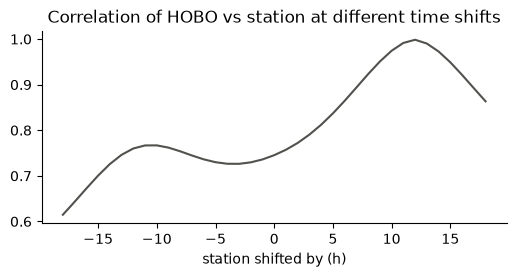

In [6]:
st = shd2["AirTC2_Avg"].resample("30min").mean()
h = hobo["T_probe1"].resample("30min").mean()
print("hour of the mean daily maximum, March 2023:")
print("  station:", st["2023-03"].groupby(st["2023-03"].index.hour).mean().idxmax(), "h")
print("  HOBO:   ", h["2023-03"].groupby(h["2023-03"].index.hour).mean().idxmax(), "h")
lags = pd.Series({k / 2: h.corr(st.shift(k)) for k in range(-36, 37, 2)}, name="correlation")
lags.index.name = "station shifted by (h)"
lags.plot(figsize=(6, 2.5), color="#52514e", title="Correlation of HOBO vs station at different time shifts")
plt.gca().spines[["top", "right"]].set_visible(False)
lags.idxmax(), round(lags.max(), 3)

The HOBO is warmest in the middle of the night, and it lines up with the station almost perfectly (r ≈ 0.997) once
shifted by **exactly 12 hours**. The AM/PM in these Flüela HOBO exports is flipped. The authors noticed too:
`scripts_figures/figure_3.m` shifts every Flüela HOBO series by `- hours(12)`, with the comment *"ist das das problem?"*
("is that the problem?"). We apply the same fix:

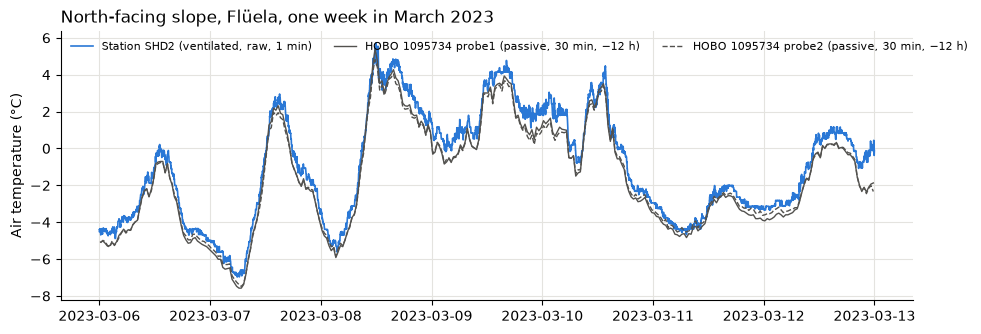

In [7]:
hobo.index = hobo.index - pd.Timedelta(hours=12)

week = slice("2023-03-06", "2023-03-12")
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(shd2.loc[week, "AirTC2_Avg"], color="#2a78d6", lw=1.2, label="Station SHD2 (ventilated, raw, 1 min)")
for c, ls in [("T_probe1", "-"), ("T_probe2", "--")]:
    ax.plot(hobo.loc[week, c], color="#52514e", lw=1, ls=ls, label=f"HOBO 1095734 {c[2:]} (passive, 30 min, −12 h)")
ax.set_ylabel("Air temperature (°C)")
ax.set_title("North-facing slope, Flüela, one week in March 2023", loc="left")
ax.legend(frameon=False, ncols=3, loc="upper left", fontsize=8)
ax.grid(color="#e4e3df", lw=0.8)
ax.spines[["top", "right"]].set_visible(False)

After the fix, the two agree closely. Raw data needs care, which is why the rest of this notebook (and the app) uses the
authors' processed files and only ports their documented corrections.

## 3. Processed data via `mat-io`

`scipy.io.loadmat` only sees MATLAB `timetable`s as opaque objects. [`mat-io`](https://pypi.org/project/mat-io/)
decodes them into pandas DataFrames. It only accepts a file path, so `Archive.mat()` copies the member
out of the zip into a temporary file that is deleted right after parsing:

In [8]:
v = ar.mat("ventilated_stations_monstein_202324.mat")
{k: (type(x).__name__, getattr(x, "shape", None)) for k, x in v.items()}

{'N_AT1': ('DataFrame', (968409, 1)),
 'N_AT2': ('DataFrame', (968409, 1)),
 'S_AT': ('DataFrame', (968409, 1)),
 'N_RH1': ('DataFrame', (968409, 1)),
 'N_RH2': ('DataFrame', (968409, 1)),
 'S_RH': ('DataFrame', (968409, 1)),
 'Ctt_MET': ('DataFrame', (968409, 7))}

In [9]:
v["Ctt_MET"].dropna().head()  # open-site weather station: air temp, RH, wind, radiation

,AT,RH,WS,WSmax,WD,SW,LW
t_comb,,,,,,,
2024-01-02 15:41:15,3.680791,53.86,2.239,2.63,52.0,45.34,309.5
2024-01-02 15:41:30,3.659791,55.46,2.430,2.73,54.0,48.58,303.9
2024-01-02 15:41:45,3.765791,54.03,2.541,2.92,43.0,50.12,299.2
2024-01-02 15:42:00,3.717791,55.35,2.557,2.87,51.0,49.70,298.6
2024-01-02 15:42:15,3.654791,55.69,2.305,2.63,44.0,49.45,298.1


`prepare.py` ports the harmonisation from `scripts_figures/figure_2.m`. The MATLAB code works with row indices,
which we translated to timestamps and checked against the authors' comments:

| season | step | as found |
|---|---|---|
| Flüela 2023 | none, 1-min data used as-is | |
| Monstein 2024 | north sensor switch at MATLAB row 531169; full minutes only; lapse-rate correction north (−0.6 K/100 m × 19 m) | switch = **2024-03-13 15:59**, matching "around 16:00h on March 13th" in the HOBO README |
| Monstein 2025 | 15-min means; south station dropped from row 70434; HOBO (1 m) fills gaps; lapse-rate correction north | cutoff = **2025-03-12 12:00**, matching "12.3. 12:00" in the script |

In [10]:
native = prepare.load_native(ar)
pd.DataFrame(
    {k: {"start": d.index.min(), "end": d.index.max(), "rows": len(d), "step": d.index.to_series().diff().median(),
         "HOBO-filled share": (d[["north_src", "south_src"]] == "hobo_1m").mean().round(2).to_dict(), **d.attrs}
     for k, d in native.items()}
).T

,start,end,rows,step,HOBO-filled share,north_sensor_switch,south_cutoff
fluela_2023,2022-11-02 09:26:00,2023-05-18 09:25:00,283680,0 days 00:01:00,"{'north_src': 0.0, 'south_src': 0.0}",NaN,NaN
monstein_2024,2023-12-12 10:47:00,2024-05-28 13:49:00,242103,0 days 00:01:00,"{'north_src': 0.0, 'south_src': 0.0}",2024-03-13 15:59:00,NaN
monstein_2025,2024-12-17 19:15:00,2025-07-31 22:45:00,21711,0 days 00:15:00,"{'north_src': 0.56, 'south_src': 0.75}",NaN,2025-03-12 12:00:00


## 4. Reproducing Figure 2

Figure 2 averages each month into a *typical day* (mean over all days, for each time of day) for both slopes. As in the
MATLAB script, a timestamp is dropped on both slopes when either is missing. `analysis.diurnal_cycle` does exactly this.

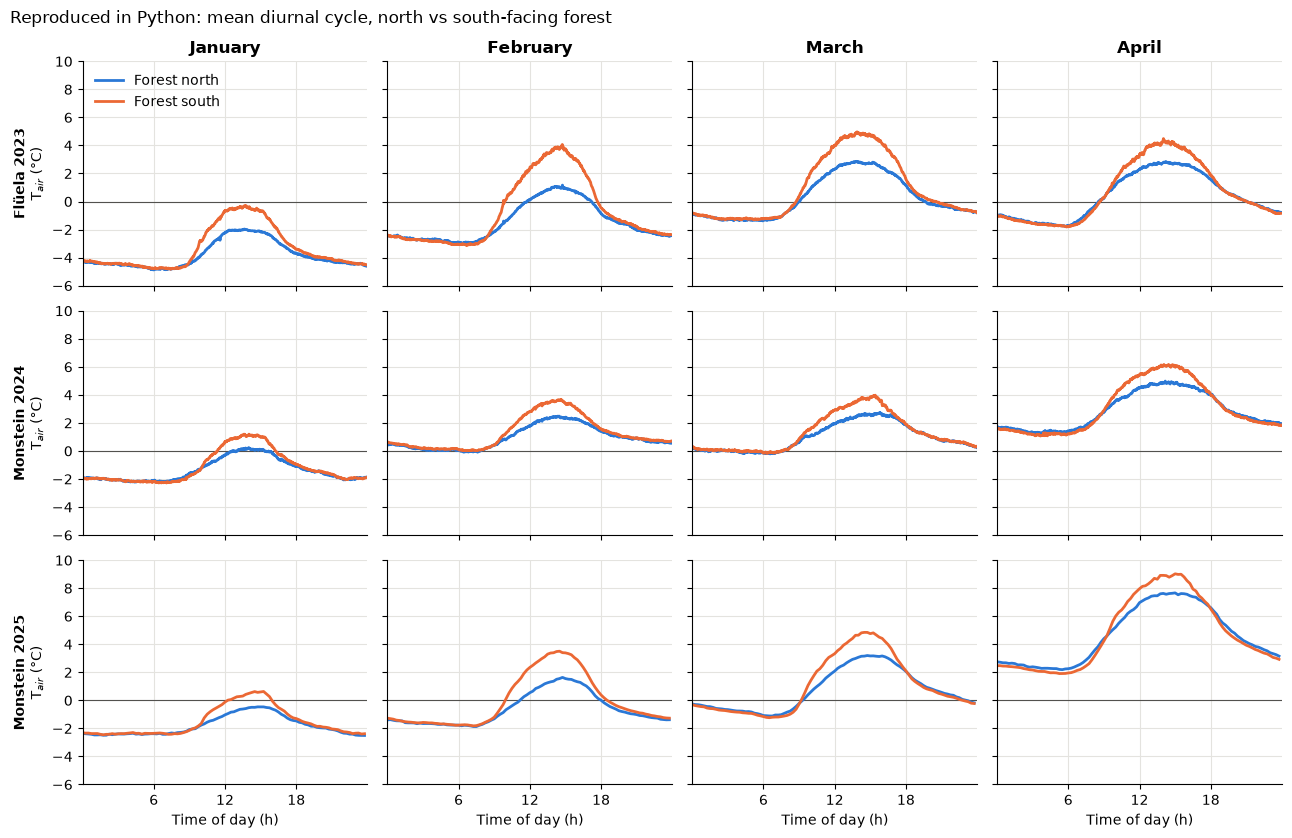

In [11]:
N, S = "#2a78d6", "#eb6834"
fig, axes = plt.subplots(3, 4, figsize=(13, 8.5), sharex=True, sharey=True)
cycles = {}
for r, (season, label) in enumerate(prepare.SEASONS.items()):
    cyc = analysis.diurnal_cycle(native[season], analysis.season_year(season))
    cycles[season] = cyc
    for c, (m, month) in enumerate(analysis.MONTHS.items()):
        ax = axes[r, c]
        d = cyc[cyc["month"] == m]
        ax.axhline(0, color="#52514e", lw=0.8)
        ax.plot(d["hour"], d["north"], color=N, lw=2, label="Forest north")
        ax.plot(d["hour"], d["south"], color=S, lw=2, label="Forest south")
        ax.set_xlim(0, 24); ax.set_ylim(-6, 10); ax.set_xticks([6, 12, 18])
        ax.grid(color="#e4e3df", lw=0.8); ax.spines[["top", "right"]].set_visible(False)
        if r == 0: ax.set_title(month, fontweight="bold")
        if c == 0: ax.set_ylabel(f"$\\bf{{{label.replace(' ', '~')}}}$\nT$_{{air}}$ (°C)")
        if r == 2: ax.set_xlabel("Time of day (h)")
axes[0, 0].legend(frameon=False, loc="upper left")
fig.suptitle("Reproduced in Python: mean diurnal cycle, north vs south-facing forest", x=0.01, ha="left")
fig.tight_layout()

And the original, straight from the archive:

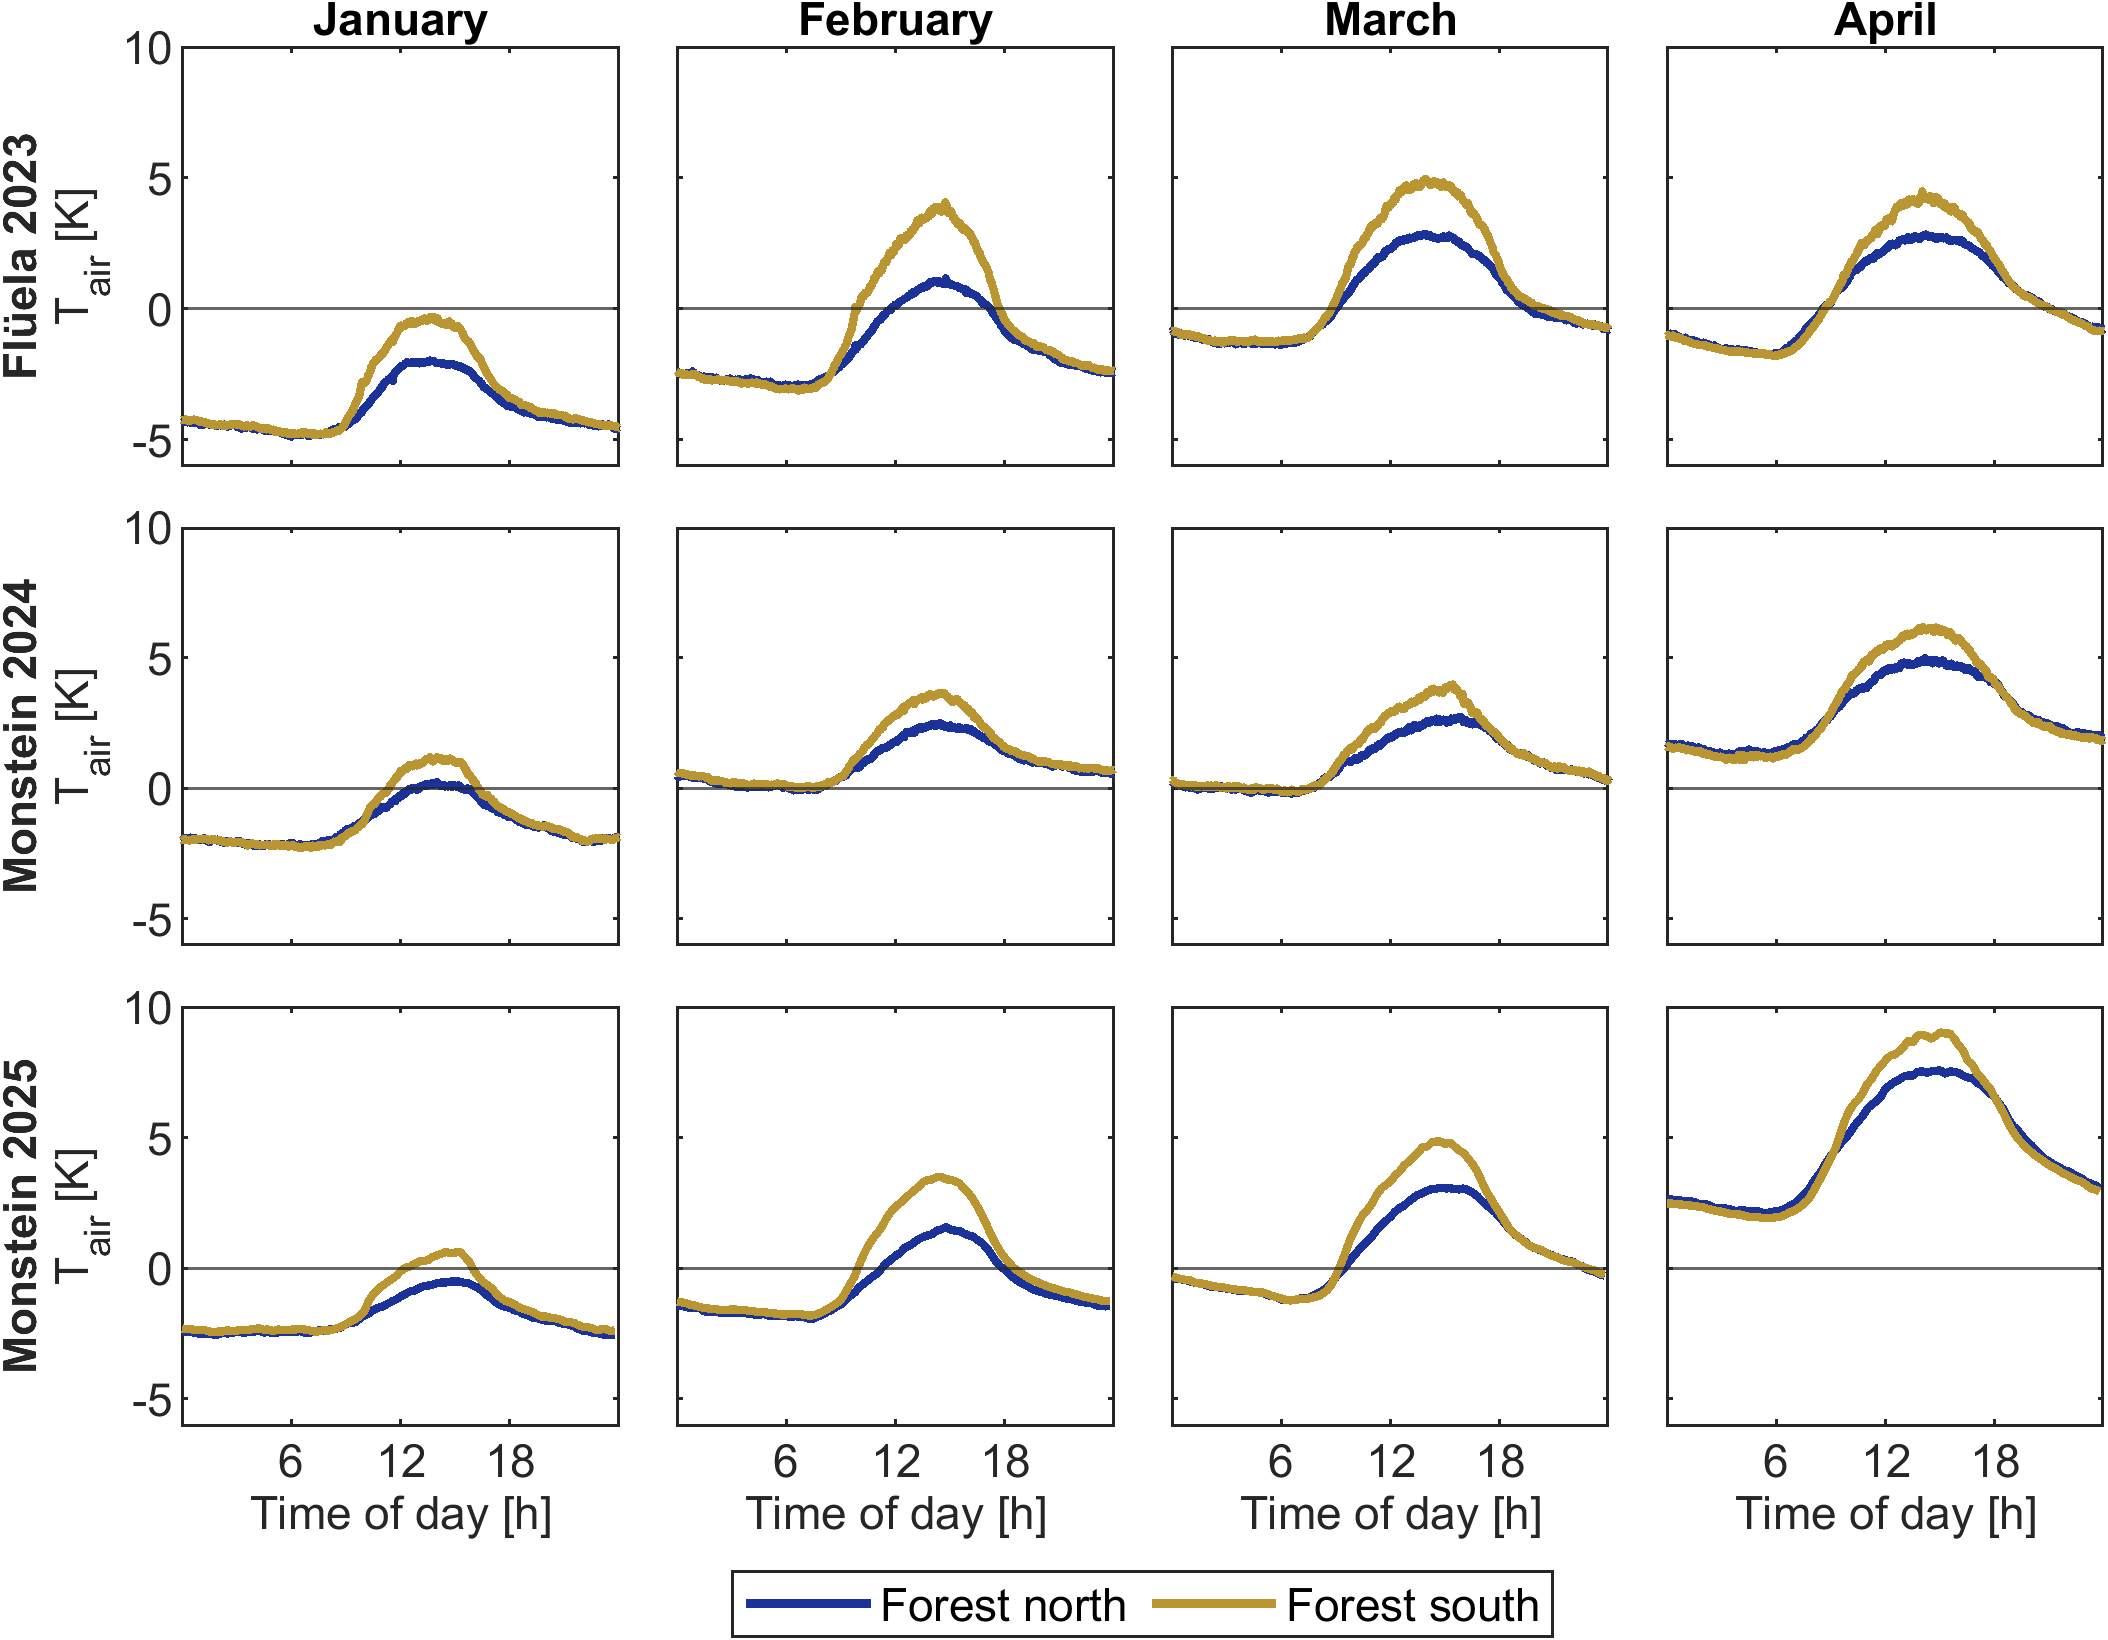

In [12]:
display(Image(ar.open("output_figures/Figure2_JGRA_Haagmans_et_al_2025.png").read(), width=900))

The curves match. The panels differ only in style (the original labels the axis "K" but plots °C).
Numerically, here is the largest south-minus-north difference in each month's mean day:

In [13]:
peaks = pd.concat(
    {prepare.SEASONS[k]: analysis.monthly_peak_contrast(c).set_index("month") for k, c in cycles.items()}, names=["season"]
)
peaks["hour"] = peaks["hour"].map(lambda h: f"{int(h):02d}:{int(round(h % 1 * 60)):02d}")
peaks.rename(columns={"hour": "time of peak", "diff": "south − north (K)"}).unstack("month").round(2)

time of peak                      south − north (K)              \
month                    1      2      3      4                 1     2     3   
season                                                                          
Flüela 2023          14:02  14:40  14:28  14:01              1.71  3.03  2.15   
Monstein 2024        14:45  14:36  15:16  14:55              1.06  1.30  1.41   
Monstein 2025        14:30  13:45  14:30  15:15              1.12  2.06  1.69   

                     
month             4  
season               
Flüela 2023    1.69  
Monstein 2024  1.35  
Monstein 2025  1.45

Every season shows the same pattern: no difference at night, then **1–3 K warmer air in the south-facing forest in the
early afternoon**. The sun reaches into the canopy on the sunny slope but not on the shady one.

## 5. The app's data

The app uses `analysis.load()`, which builds the same harmonised series from the zip but averages them to 15 min. That gives
one common time step for all seasons and keeps the interactive plots light. Does it tell the same story?

In [14]:
temps, snow = analysis.load(ZIP)
rows = []
for season in prepare.SEASONS:
    a = analysis.monthly_peak_contrast(cycles[season]).set_index("month")["diff"]
    b = analysis.monthly_peak_contrast(
        analysis.diurnal_cycle(analysis.season_frame(temps, season), analysis.season_year(season))
    ).set_index("month")["diff"]
    rows.append(pd.DataFrame({"native": a, "15-min (app)": b, "abs. difference": (a - b).abs()}).assign(season=season))
pd.concat(rows).set_index("season", append=True).swaplevel().round(2)

native  15-min (app)  abs. difference
season        month                                       
fluela_2023   1        1.71          1.64             0.07
              2        3.03          2.90             0.13
              3        2.15          2.09             0.06
              4        1.69          1.52             0.17
monstein_2024 1        1.06          1.01             0.05
              2        1.30          1.24             0.06
              3        1.41          1.31             0.11
              4        1.35          1.25             0.10
monstein_2025 1        1.12          1.12             0.00
              2        2.06          2.06             0.00
              3        1.69          1.69             0.00
              4        1.45          1.45             0.00

Within about 0.15 K, mostly because 15-min means smooth the 1-min peaks slightly. That's good enough for an interactive overview.

**Next:** run the app with `panel serve app.py --show` (or open the Renku app launcher) to explore each season interactively,
including the full-season timeline with snow-cover periods.